In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_table("../data/NV2g.20240221.geneNames.txt")
df = df.dropna(subset=["name"])
df.head()

,id,main_id,name,sym,source_id,oma_group_id
0,NV2t009957001.1,SELF,NV2t009957001.1,NaN,0,0
1,NV2t005400001.1,SELF,aurora kinase A,AURKA,OMA|OrthologousGroup|HUMAN|ENSG00000087586,OMAGROUP|OGNone
2,NV2t011205001.1,SELF,KAT8 regulatory NSL complex subunit 1,KANSL1,OMA|1to1|ENS|HUMAN|ENSG00000120071,OMAGROUP|OG1052381
3,NV2t014228001.1,SELF,Filamin-A,Flna,UNIPROT|Mus musculus|Q8BTM8|6.66e-07,0
4,NV2t006138001.1,SELF,Derived by automated computational analysis us...,0,OMA|1to1|MultiGroup|MULTI|OG845447(HAECO17377)...,"OMAGROUP|OGMULTI|OG845447(HAECO17377),OG845447..."


In [4]:
rna_counts = pd.read_table("rna_counts.txt")
rna_counts.columns = ["id", "Chr", "Start", "End", "Strand", "Length", "N1", "N2", "N3"]
rna_counts.head()

,id,Chr,Start,End,Strand,Length,N1,N2,N3
0,NV2g025931000.1,chrUn3,1176,35911,+,34736,100,91,149
1,NV2g025877000.1,chrUn2;chrUn2;chrUn2;chrUn2,1353;1763;2502;3123,1582;1937;2659;3171,-;-;-;-,612,3,41,7
2,NV2g025878000.1,chrUn2;chrUn2,3182;5677,3230;5846,+;+,219,6,29,6
3,NV2g025879000.1,chrUn2;chrUn2;chrUn2;chrUn2;chrUn2;chrUn2,5660;7925;8937;9244;9993;11624,5844;8040;9078;9385;10098;11862,-;-;-;-;-;-,930,3,2,2
4,NV2g025880000.1,chrUn2;chrUn2,12091;12879,12508;14704,+;+,2244,9,12,5


In [5]:
rna_counts["gene_id"] = [g[5:11] for g in rna_counts["id"]]
rna_counts.head()

,id,Chr,Start,End,Strand,Length,N1,N2,N3,gene_id
0,NV2g025931000.1,chrUn3,1176,35911,+,34736,100,91,149,259310
1,NV2g025877000.1,chrUn2;chrUn2;chrUn2;chrUn2,1353;1763;2502;3123,1582;1937;2659;3171,-;-;-;-,612,3,41,7,258770
2,NV2g025878000.1,chrUn2;chrUn2,3182;5677,3230;5846,+;+,219,6,29,6,258780
3,NV2g025879000.1,chrUn2;chrUn2;chrUn2;chrUn2;chrUn2;chrUn2,5660;7925;8937;9244;9993;11624,5844;8040;9078;9385;10098;11862,-;-;-;-;-;-,930,3,2,2,258790
4,NV2g025880000.1,chrUn2;chrUn2,12091;12879,12508;14704,+;+,2244,9,12,5,258800


In [6]:
df["gene_id"] = [g[5:11] for g in df["id"]]
df.head()

,id,main_id,name,sym,source_id,oma_group_id,gene_id
0,NV2t009957001.1,SELF,NV2t009957001.1,NaN,0,0,099570
1,NV2t005400001.1,SELF,aurora kinase A,AURKA,OMA|OrthologousGroup|HUMAN|ENSG00000087586,OMAGROUP|OGNone,054000
2,NV2t011205001.1,SELF,KAT8 regulatory NSL complex subunit 1,KANSL1,OMA|1to1|ENS|HUMAN|ENSG00000120071,OMAGROUP|OG1052381,112050
3,NV2t014228001.1,SELF,Filamin-A,Flna,UNIPROT|Mus musculus|Q8BTM8|6.66e-07,0,142280
4,NV2t006138001.1,SELF,Derived by automated computational analysis us...,0,OMA|1to1|MultiGroup|MULTI|OG845447(HAECO17377)...,"OMAGROUP|OGMULTI|OG845447(HAECO17377),OG845447...",061380


In [7]:
genes_with_counts = df.merge(rna_counts, left_on="gene_id", right_on="gene_id")
genes_with_counts.head()

,id_x,main_id,name,sym,source_id,oma_group_id,gene_id,id_y,Chr,Start,End,Strand,Length,N1,N2,N3
0,NV2t009957001.1,SELF,NV2t009957001.1,NaN,0,0,099570,NV2g009957000.1,chr15;chr15;chr15;chr15;chr15;chr15;chr15;chr1...,5165305;5165305;5165305;5165399;5165399;516688...,5165630;5165630;5165630;5165630;5165630;516714...,-;-;-;-;-;-;-;-;-;-;-;-;-;-;-;-;-;-,857,11,7,10
1,NV2t005400001.1,SELF,aurora kinase A,AURKA,OMA|OrthologousGroup|HUMAN|ENSG00000087586,OMAGROUP|OGNone,054000,NV2g005400000.1,chr11;chr11;chr11;chr11;chr11;chr11;chr11;chr1...,14115871;14116069;14116637;14116882;14117388;1...,14115983;14116132;14116812;14116928;14117449;1...,+;+;+;+;+;+;+;+;+;+;+;+,1765,509,558,659
2,NV2t011205001.1,SELF,KAT8 regulatory NSL complex subunit 1,KANSL1,OMA|1to1|ENS|HUMAN|ENSG00000120071,OMAGROUP|OG1052381,112050,NV2g011205000.1,chr2;chr2;chr2;chr2;chr2;chr2;chr2;chr2,5091263;5093447;5096464;5097489;5098264;509857...,5091712;5095299;5097164;5097597;5098331;509871...,+;+;+;+;+;+;+;+,5057,1348,1357,1581
3,NV2t014228001.1,SELF,Filamin-A,Flna,UNIPROT|Mus musculus|Q8BTM8|6.66e-07,0,142280,NV2g014228000.1,chr3;chr3;chr3,10296857;10299795;10300054,10298227;10299930;10300207,-;-;-,1661,135,140,165
4,NV2t006138001.1,SELF,Derived by automated computational analysis us...,0,OMA|1to1|MultiGroup|MULTI|OG845447(HAECO17377)...,"OMAGROUP|OGMULTI|OG845447(HAECO17377),OG845447...",061380,NV2g006138000.1,chr12,7246487,7254907,+,8421,73,79,105


In [8]:
genes_with_counts.shape

(35568, 16)

In [27]:
genes_with_counts["is_gpcr"] = ["G-protein coupled receptor" in n for n in genes_with_counts["name"]]
genes_with_counts["is_ionchannel"] = ["ion channel" in n for n in genes_with_counts["name"]]
genes_with_counts["is_receptor"] = ["receptor" in n for n in genes_with_counts["name"]]
genes_with_counts.head()

,id_x,main_id,name,sym,source_id,oma_group_id,gene_id,id_y,Chr,Start,End,Strand,Length,N1,N2,N3,is_gpcr,is_ionchannel,is_receptor
0,NV2t009957001.1,SELF,NV2t009957001.1,NaN,0,0,099570,NV2g009957000.1,chr15;chr15;chr15;chr15;chr15;chr15;chr15;chr1...,5165305;5165305;5165305;5165399;5165399;516688...,5165630;5165630;5165630;5165630;5165630;516714...,-;-;-;-;-;-;-;-;-;-;-;-;-;-;-;-;-;-,857,11,7,10,False,False,False
1,NV2t005400001.1,SELF,aurora kinase A,AURKA,OMA|OrthologousGroup|HUMAN|ENSG00000087586,OMAGROUP|OGNone,054000,NV2g005400000.1,chr11;chr11;chr11;chr11;chr11;chr11;chr11;chr1...,14115871;14116069;14116637;14116882;14117388;1...,14115983;14116132;14116812;14116928;14117449;1...,+;+;+;+;+;+;+;+;+;+;+;+,1765,509,558,659,False,False,False
2,NV2t011205001.1,SELF,KAT8 regulatory NSL complex subunit 1,KANSL1,OMA|1to1|ENS|HUMAN|ENSG00000120071,OMAGROUP|OG1052381,112050,NV2g011205000.1,chr2;chr2;chr2;chr2;chr2;chr2;chr2;chr2,5091263;5093447;5096464;5097489;5098264;509857...,5091712;5095299;5097164;5097597;5098331;509871...,+;+;+;+;+;+;+;+,5057,1348,1357,1581,False,False,False
3,NV2t014228001.1,SELF,Filamin-A,Flna,UNIPROT|Mus musculus|Q8BTM8|6.66e-07,0,142280,NV2g014228000.1,chr3;chr3;chr3,10296857;10299795;10300054,10298227;10299930;10300207,-;-;-,1661,135,140,165,False,False,False
4,NV2t006138001.1,SELF,Derived by automated computational analysis us...,0,OMA|1to1|MultiGroup|MULTI|OG845447(HAECO17377)...,"OMAGROUP|OGMULTI|OG845447(HAECO17377),OG845447...",061380,NV2g006138000.1,chr12,7246487,7254907,+,8421,73,79,105,False,False,False


In [ ]:
genes_with_counts[genes_with_counts["is_gpcr"] == True].head()

,id_x,main_id,name,sym,source_id,oma_group_id,gene_id,id_y,Chr,Start,End,Strand,Length,N1,N2,N3,is_gpcr,is_ionchannel,is_receptor
1168,NV2t019080003.1,NV2t019080001.1,G-protein coupled receptor GRL101,0,UNIPROT|0|P46023|3.95e-87,0,190800,NV2g019080000.1,chr5;chr5;chr5;chr5;chr5;chr5;chr5;chr5;chr5;c...,15072128;15072128;15072905;15072905;15073408;1...,15072541;15072541;15072984;15072984;15073562;1...,-;-;-;-;-;-;-;-;-;-;-;-;-;-;-;-;-;-;-;-;-;-;-;...,10183,232,238,309,True,False,True
1592,NV2t000801005.1,NV2t000801001.1,Adhesion G-protein coupled receptor G6,adgrg6,UNIPROT|Danio rerio|C6KFA3|9.58e-48,0,008010,NV2g000801000.1,chr1;chr1;chr1;chr1;chr1;chr1;chr1;chr1;chr1;c...,7480806;7480806;7480807;7480807;7480807;748182...,7481584;7481591;7481575;7481575;7481575;748291...,-;-;-;-;-;-;-;-;-;-;-;-;-;-;-;-;-;-;-;-;-;-;-;...,6380,1639,1620,1751,True,False,True
2014,NV2t018839001.1,SELF,G-protein coupled receptor 83,Gpr83,UNIPROT|Rattus norvegicus|Q8VHD7|6.24e-25,0,188390,NV2g018839000.1,chr5;chr5;chr5,12917879;12931696;12944192,12920127;12931784;12944223,-;-;-,2370,57,60,67,True,False,True
2182,NV2t000674001.1,SELF,Adhesion G-protein coupled receptor G4,Adgrg4,UNIPROT|Mus musculus|B7ZCC9|8.62e-59,0,006740,NV2g000674000.1,chr1;chr1;chr1;chr1;chr1;chr1;chr1;chr1;chr1;c...,6308887;6312139;6312895;6313465;6314231;631470...,6309056;6312265;6313108;6313612;6314415;631484...,+;+;+;+;+;+;+;+;+;+;+;+;+;+;+;+;+;+;+;+,5830,322,361,399,True,False,True
2486,NV2t013314002.1,NV2t013314001.1,G-protein coupled receptor,0,OMA|1to1|MultiGroup|MULTI|OG789229(PTEVA16506),OMAGROUP|OGMULTI|OG789229(PTEVA16506),133140,NV2g013314000.1,chr3;chr3;chr3;chr3;chr3,2368170;2368170;2376419;2376419;2376666,2370733;2370733;2376734;2376544;2376734,-;-;-;-;-,2880,6,20,11,True,False,True


In [30]:
gpcrs = genes_with_counts[genes_with_counts["is_gpcr"] == True].filter(items=["id_x", "main_id", "name", "gene_id", "length", "N1", "N2", "N3"])
gpcrs.head()

,id_x,main_id,name,gene_id,N1,N2,N3
1168,NV2t019080003.1,NV2t019080001.1,G-protein coupled receptor GRL101,190800,232,238,309
1592,NV2t000801005.1,NV2t000801001.1,Adhesion G-protein coupled receptor G6,008010,1639,1620,1751
2014,NV2t018839001.1,SELF,G-protein coupled receptor 83,188390,57,60,67
2182,NV2t000674001.1,SELF,Adhesion G-protein coupled receptor G4,006740,322,361,399
2486,NV2t013314002.1,NV2t013314001.1,G-protein coupled receptor,133140,6,20,11


In [ ]:
gpcrs.to_csv("gpcr_counts.csv")

In [32]:
ion_channels = genes_with_counts[genes_with_counts["is_ionchannel"] == True].filter(items=["id_x", "main_id", "name", "gene_id", "length", "N1", "N2", "N3"])
ion_channels.to_csv("ionchannel_counts.csv")
receptors = genes_with_counts[genes_with_counts["is_receptor"] == True].filter(items=["id_x", "main_id", "name", "gene_id", "length", "N1", "N2", "N3"])
receptors.to_csv("receptor_counts.csv")

In [35]:
gpcrs["avg_counts"] = (gpcrs["N1"] + gpcrs["N2"] + gpcrs["N3"]) / 3
gpcrs.sort_values(by=["avg_counts", "N1", "N2", "N3"], ascending=False).to_csv("gpcr_counts_sorted.csv")

Text(0.5, 1.0, 'Average RNA counts for GPCRs')

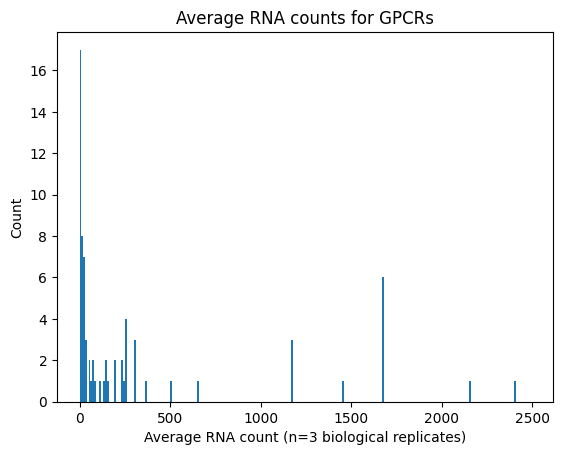

In [38]:
#histogram of average count distribution
import matplotlib.pyplot as plt
plt.hist(gpcrs["avg_counts"], bins=np.arange(0, 2500, 10))
plt.xlabel("Average RNA count (n=3 biological replicates)")
plt.ylabel("Count")
plt.title("Average RNA counts for GPCRs")

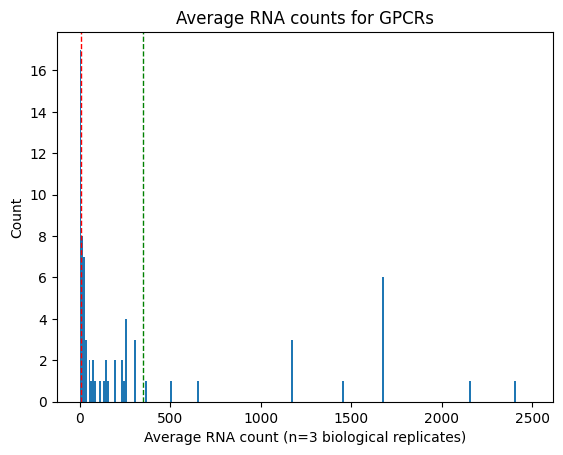

In [43]:
plt.hist(gpcrs["avg_counts"], bins=np.arange(0, 2500, 10))
plt.xlabel("Average RNA count (n=3 biological replicates)")
plt.ylabel("Count")
plt.title("Average RNA counts for GPCRs")
plt.axvline(10, color='red', linestyle='dashed', linewidth=1)
plt.axvline(gpcrs["avg_counts"].mean(), color='green', linestyle='dashed', linewidth=1)

Text(0.5, 1.0, 'Average RNA counts for Ion Channels')

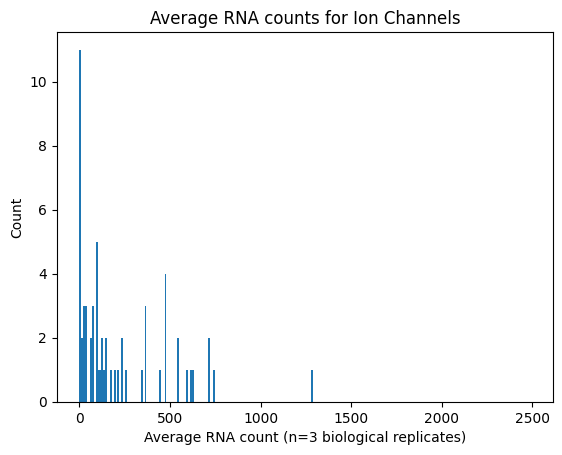

In [40]:
ion_channels["avg_counts"] = (ion_channels["N1"] + ion_channels["N2"] + ion_channels["N3"]) / 3
plt.hist(ion_channels["avg_counts"], bins=np.arange(0, 2500, 10))
plt.xlabel("Average RNA count (n=3 biological replicates)")
plt.ylabel("Count")
plt.title("Average RNA counts for Ion Channels")

Text(0.5, 1.0, 'Average RNA counts for Receptors')

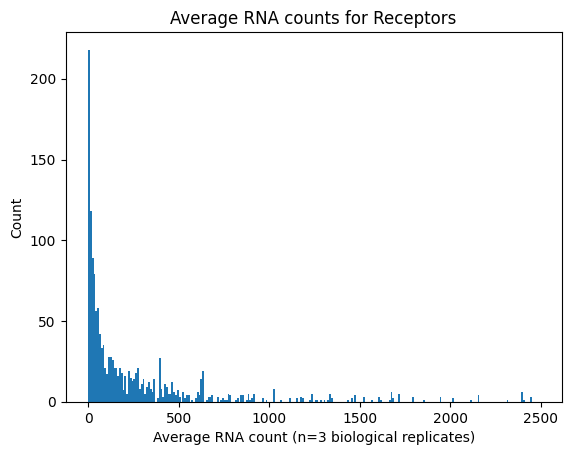

In [41]:
receptors["avg_counts"] = (receptors["N1"] + receptors["N2"] + receptors["N3"]) / 3
plt.hist(receptors["avg_counts"], bins=np.arange(0, 2500, 10))
plt.xlabel("Average RNA count (n=3 biological replicates)")
plt.ylabel("Count")
plt.title("Average RNA counts for Receptors")

### Below: Old work that is now worthless as I have figured out a better way to match genes across the two DFs above.

In [ ]:
#since the gene ids are used in the RNA counts and the transcript IDs are used in the gene names,
#in order to properly map stuff we're going to need a gene to transcript conversion. 
#that's what this section is about.

gtf = pd.read_table("../data/NV2g.20240221.gtf")
#gtf.head()

#since we're just wanting to map transcript ids to gene ids, we don't lose anything valuable by getting rid of the first row
#which is automatically read as the column titles
gtf.columns = [1, 2, 3, 4, 5, 6, 7, 8, 9]
transcript_ids = [g[15:30] for g in gtf[9]]
gene_ids = [g[42:57] for g in gtf[9]]
gtf["transcript_id"] = transcript_ids
gtf["gene_id"] = gene_ids
gtf.head()

In [ ]:
transcript_to_gene = pd.concat([gtf["transcript_id"], gtf["gene_id"]], axis=1)
transcript_to_gene.to_csv("../data/transcript_to_gene.csv")

In [ ]:
#now that we've gotten a transcript to gene converter, we can actually merge these into a consistent dataframe.
#hopefully. 
#first i'll make a dictionary converter. There's probably an easier way to do this but that's a problem for a later time
converter = {}
for i in range(len(transcript_to_gene)):
    g = transcript_to_gene.iloc[i]["gene_id"]
    t = transcript_to_gene.iloc[i]["transcript_id"]
    converter[g] = t

converter

In [ ]:
#it was at this point I realized that the gene id, which is the first 6 numbers after NV2t/NV2g remains the same
#but I'm not going to let my hard work go to waste here man.
#pickle this.
import pickle
with open("gene_to_transcript_converter.pkl", "wb") as file:
    pickle.dump(converter, file)